# 02 · How a Bit Is Hidden — QIM on a Singular Value

**Project:** SVD-based digital watermarking & steganography (course 01076020)

**What this notebook answers**
1. *How exactly is one bit hidden in an 8×8 block?* (one block, step by step, with real pixels)
2. *Does it work on a whole image, and what does it cost?* (picture quality and bit errors)
3. *Why 8×8 blocks?* (the honest answer, with numbers from our data)

**The idea in one paragraph.** Take an 8×8 block of pixels and compute its SVD. Pick one singular value σ.
Draw a ruler with marks every Δ units. Marks alternate: **even marks mean bit 0, odd marks mean bit 1**.
To hide a bit, slide σ to the *nearest mark that carries that bit*. Rebuild the block from the changed σ.
To read the bit back, compute σ of the received block, find the nearest mark, and check whether it is even or odd.

| Symbol | Meaning |
|---|---|
| σₖ | the singular value we modify (here k = 2, written σ₂) |
| Δ (step size) | distance between two marks on the ruler |
| q = round(σ / Δ) | which mark σ is closest to; q even → 0, q odd → 1 |
| cover / stego image | the original image / the image with the hidden bits |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, ORANGE, GRAY = "#2f6db5", "#c2410c", "#6b7280"
pd.options.display.float_format = "{:,.2f}".format

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
manifest = pd.read_csv(ROOT / "results" / "clean_manifest.csv")
B, K = 8, 1            # block size, index of the singular value used (K = 1 means sigma_2)

def load_gray_crop(split, name, b=B):
    with Image.open(ROOT / "data" / "images" / split / name) as im:
        g = np.asarray(im.convert("L"), dtype=np.float64)
    h, w = g.shape[0] // b * b, g.shape[1] // b * b
    t, l = (g.shape[0] - h) // 2, (g.shape[1] - w) // 2
    return g[t:t + h, l:l + w]

def blocks_of(a, b=B):
    H, W = a.shape
    return a.reshape(H // b, b, W // b, b).swapaxes(1, 2).reshape(-1, b, b)

def image_of(blocks, shape, b=B):
    H, W = shape
    return blocks.reshape(H // b, W // b, b, b).swapaxes(1, 2).reshape(H, W)

# ---- the two rules that define QIM -------------------------------------------------
def qim_embed(sigma, bit, delta):
    """Move sigma to the nearest multiple of delta whose index q has parity == bit."""
    q = np.rint(sigma / delta)
    step = np.where(sigma / delta >= q, 1.0, -1.0)         # which neighbour is nearer
    q = np.where((q % 2) != bit, q + step, q)
    return q * delta

def qim_extract(sigma, delta):
    return (np.rint(sigma / delta) % 2).astype(int)

def psnr(a, b):
    mse = np.mean((a - b) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)
print("Helpers ready.")

Helpers ready.


## 1. One block, step by step

We take one real 8×8 block, compute its SVD, and hide **bit 0** and **bit 1** in σ₂ with step size Δ = 16.
The block is chosen so that σ₂ is clearly larger than Δ (a "safe" block, see notebook 01 section 6).

In [2]:
DELTA = 16
row = manifest[manifest["split"] == "train"].iloc[3]
A = load_gray_crop(row["split"], row["filename"])
blks = blocks_of(A)
S_all = np.linalg.svd(blks, compute_uv=False)
mid_tone = (blks.max(axis=(1, 2)) < 235) & (blks.min(axis=(1, 2)) > 20)      # avoid pure-white / pure-black blocks
cand = np.where((S_all[:, 1] > 55) & (S_all[:, 1] < 75) & (S_all[:, 2] < 0.6 * S_all[:, 1]) & mid_tone)[0]
bi = int(cand[len(cand) // 2])
blk = blks[bi]
U, s, Vt = np.linalg.svd(blk)
print(f"Image {row['filename']}, block #{bi}.")
print("Singular values of this block:", ", ".join(f"σ{i+1}={v:.1f}" for i, v in enumerate(s)))
sig = s[K]
q0 = np.rint(sig / DELTA)
print(f"\nσ₂ = {sig:.2f}.  With Δ = {DELTA}:  σ₂ / Δ = {sig/DELTA:.2f}  →  nearest mark q = {q0:.0f}  ({'even → currently reads as 0' if q0 % 2 == 0 else 'odd → currently reads as 1'})")

Image 103041.jpg, block #1570.
Singular values of this block: σ1=1451.6, σ2=58.2, σ3=32.5, σ4=21.6, σ5=18.2, σ6=17.3, σ7=2.6, σ8=0.8

σ₂ = 58.19.  With Δ = 16:  σ₂ / Δ = 3.64  →  nearest mark q = 4  (even → currently reads as 0)


### 1a. The ruler

Blue marks = even multiples of Δ (bit **0**), orange marks = odd multiples (bit **1**). The black dot is the block's σ₂.
The arrow shows where σ₂ must move to carry the wanted bit. If σ₂ already sits on the right kind of mark, it moves to the nearest mark of that colour (possibly zero distance away).

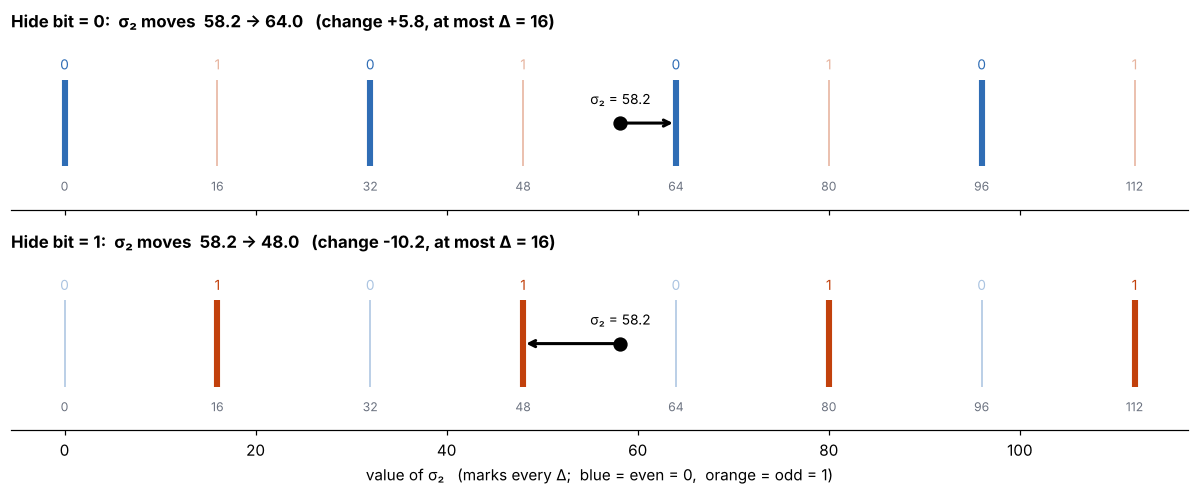

In [3]:
new = {b: float(qim_embed(sig, b, DELTA)) for b in (0, 1)}
hi = (np.rint(sig / DELTA) + 3) * DELTA
fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
for ax, bit in zip(axes, (0, 1)):
    for q in range(0, int(hi / DELTA) + 1):
        right = (q % 2 == bit)
        col = BLUE if q % 2 == 0 else ORANGE
        ax.plot([q * DELTA] * 2, [0, 1], color=col, lw=4 if right else 1.2, alpha=1 if right else 0.35, solid_capstyle="butt")
        ax.text(q * DELTA, -0.28, f"{q*DELTA:.0f}", ha="center", fontsize=8, color=GRAY)
        ax.text(q * DELTA, 1.12, "0" if q % 2 == 0 else "1", ha="center", fontsize=9, color=col, alpha=1 if right else 0.4)
    ax.scatter([sig], [0.5], s=70, color="black", zorder=5)
    ax.text(sig, 0.72, f"σ₂ = {sig:.1f}", ha="center", fontsize=9)
    if abs(new[bit] - sig) > 1e-9:
        ax.annotate("", xy=(new[bit], 0.5), xytext=(sig, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color="black"))
    ax.set_ylim(-0.5, 1.5); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(f"Hide bit = {bit}:  σ₂ moves  {sig:.1f} → {new[bit]:.1f}   (change {new[bit]-sig:+.1f}, at most Δ = {DELTA})", loc="left")
axes[1].set_xlabel("value of σ₂   (marks every Δ;  blue = even = 0,  orange = odd = 1)")
plt.tight_layout(); plt.show()

### 1b. What happens to the pixels

We rebuild the block from the modified σ₂ (same U and V, only one singular value changes), then round to whole gray levels like a real image file.
Right-hand panels show the **difference** from the original block, in gray levels.

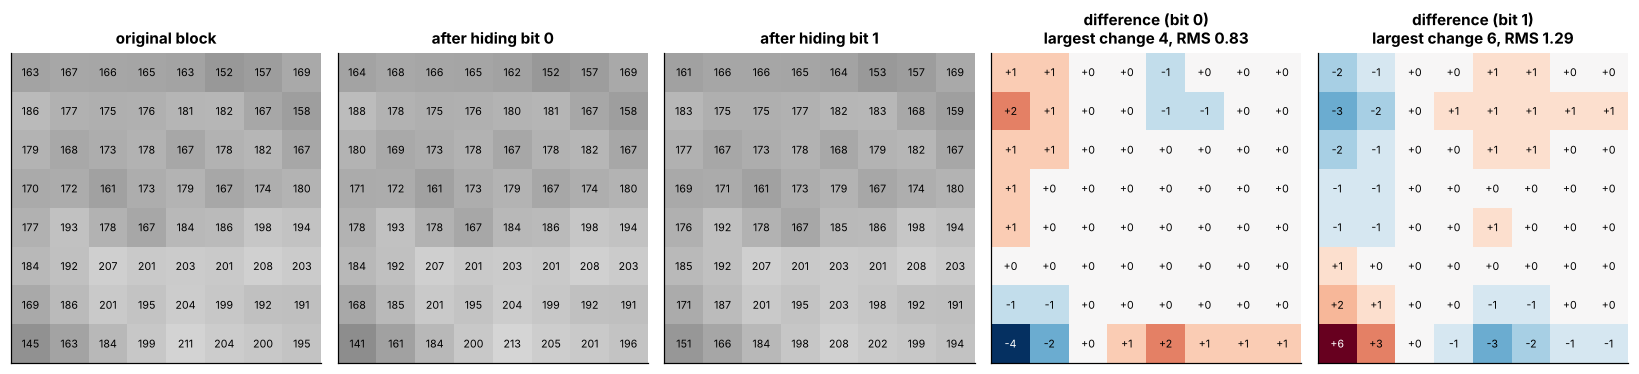

Bit 0: read back σ₂ = 64.48  →  mark q = 4  →  extracted bit = 0  (OK)
Bit 1: read back σ₂ = 48.18  →  mark q = 3  →  extracted bit = 1  (OK)


In [4]:
def rebuild(U, s, Vt, k, newval):
    s2 = s.copy(); s2[k] = newval
    return np.clip(np.rint((U * s2) @ Vt), 0, 255)

stego = {b: rebuild(U, s, Vt, K, new[b]) for b in (0, 1)}
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
def show(a, a_ax, title, vmin=0, vmax=255, cmap="gray", fmt="{:.0f}"):
    a_ax.imshow(a, cmap=cmap, vmin=vmin, vmax=vmax)
    for i in range(B):
        for j in range(B):
            v = a[i, j]
            dark = (v < (vmin + vmax) / 2) if cmap == "gray" else abs(v) > 0.6 * max(abs(vmin), abs(vmax))
            a_ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7, color="white" if dark else "black")
    a_ax.set_title(title, fontsize=10); a_ax.set_xticks([]); a_ax.set_yticks([])
show(blk, ax[0], "original block")
show(stego[0], ax[1], "after hiding bit 0")
show(stego[1], ax[2], "after hiding bit 1")
for a_ax, b in ((ax[3], 0), (ax[4], 1)):
    d = stego[b] - blk; lim = max(3, np.abs(d).max())
    show(d, a_ax, f"difference (bit {b})\nlargest change {np.abs(d).max():.0f}, RMS {np.sqrt((d**2).mean()):.2f}", -lim, lim, "RdBu_r", "{:+.0f}")
plt.tight_layout(); plt.show()

for b in (0, 1):
    s_back = np.linalg.svd(stego[b], compute_uv=False)[K]
    print(f"Bit {b}: read back σ₂ = {s_back:.2f}  →  mark q = {np.rint(s_back/DELTA):.0f}  →  extracted bit = {int(qim_extract(s_back, DELTA))}  ({'OK' if qim_extract(s_back, DELTA)==b else 'ERROR'})")

In [5]:
d0, d1 = stego[0] - blk, stego[1] - blk
display(Markdown(f"""**Takeaway.** The 64 pixels change only by a few gray levels (RMS {np.sqrt((d0**2).mean()):.2f} for bit 0, {np.sqrt((d1**2).mean()):.2f} for bit 1),
while σ₂ moves by at most Δ = {DELTA}. A gray-level change of 1 to 3 on a 0–255 scale is usually hard to see in a textured block.
The bit is read back from σ₂ of the **rounded** block, so the rounding to whole pixels is already included in the check above."""))

**Takeaway.** The 64 pixels change only by a few gray levels (RMS 0.83 for bit 0, 1.29 for bit 1),
while σ₂ moves by at most Δ = 16. A gray-level change of 1 to 3 on a 0–255 scale is usually hard to see in a textured block.
The bit is read back from σ₂ of the **rounded** block, so the rounding to whole pixels is already included in the check above.

## 2. A whole image

Now every 8×8 block of one image receives one random bit (σ₂, Δ as set below). Then we measure:
* **PSNR** (picture quality, dB; higher = closer to the original; above about 40 dB differences are hardly visible),
* **BER** (bit error rate; the share of hidden bits that are read back wrongly; 0 is perfect),
* the same after adding **random noise** to the stego image, to see how robust each Δ is.

Image 102062.jpg: 480×320 pixels (width × height) → 2400 blocks → 2400 hidden bits.
PSNR(cover, stego) = 46.8 dB     BER without any attack = 1.12%


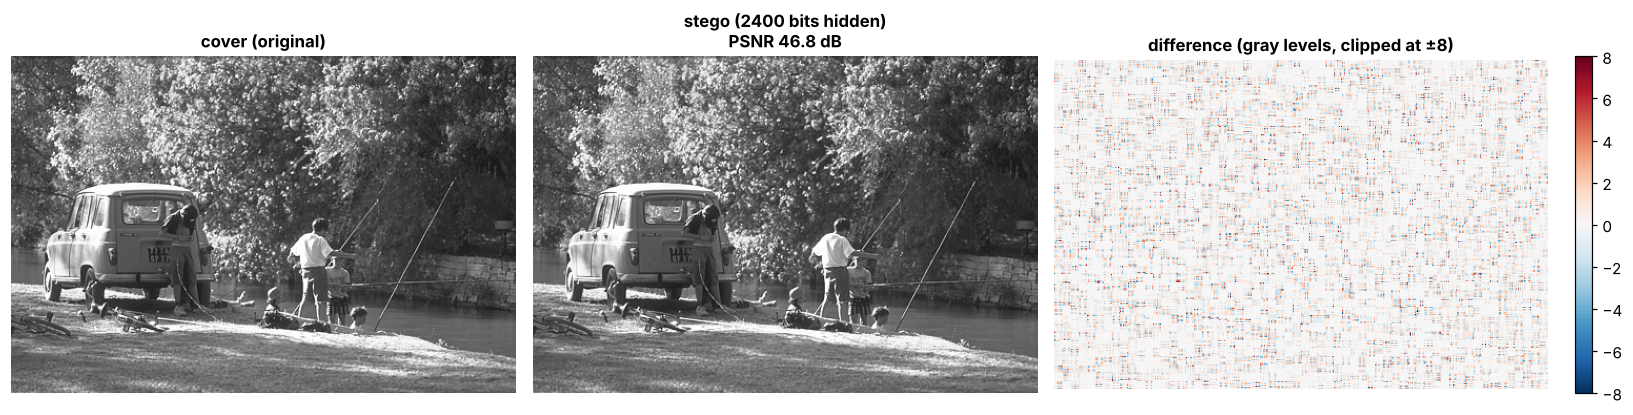

In [6]:
def embed_image(A, bits, delta, k=K):
    bl = blocks_of(A)
    U, s, Vt = np.linalg.svd(bl)
    s[:, k] = qim_embed(s[:, k], bits, delta)
    out = np.einsum("nij,nj,njk->nik", U, s, Vt)
    return image_of(np.clip(np.rint(out), 0, 255), A.shape)

def extract_image(A, delta, k=K):
    return qim_extract(np.linalg.svd(blocks_of(A), compute_uv=False)[:, k], delta)

key = manifest[(manifest["split"] == "test") & (manifest["width"] > manifest["height"])].iloc[5]   # a landscape image
cover = load_gray_crop(key["split"], key["filename"])
n_bits = (cover.shape[0] // B) * (cover.shape[1] // B)
rng = np.random.default_rng(0)
bits = rng.integers(0, 2, n_bits)
stego_img = embed_image(cover, bits, DELTA)
rec = extract_image(stego_img, DELTA)
print(f"Image {key['filename']}: {cover.shape[1]}×{cover.shape[0]} pixels (width × height) → {n_bits} blocks → {n_bits} hidden bits.")
print(f"PSNR(cover, stego) = {psnr(cover, stego_img):.1f} dB     BER without any attack = {np.mean(rec != bits)*100:.2f}%")

diff = stego_img - cover
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.08]})
ax[0].imshow(cover, cmap="gray", vmin=0, vmax=255); ax[0].set_title("cover (original)")
ax[1].imshow(stego_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title(f"stego ({n_bits} bits hidden)\nPSNR {psnr(cover, stego_img):.1f} dB")
im = ax[2].imshow(diff, cmap="RdBu_r", vmin=-8, vmax=8); ax[2].set_title("difference (gray levels, clipped at ±8)")
plt.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [7]:
rows = []
for d in (8, 16, 32):
    st = embed_image(cover, bits, d)
    row_ = {"Step size Δ": d, "PSNR (dB)": psnr(cover, st)}
    for sd in (0, 1, 2, 4):
        noisy = np.clip(np.rint(st + np.random.default_rng(1).normal(0, sd, st.shape)), 0, 255) if sd else st
        row_[f"BER, noise std {sd} (%)"] = np.mean(extract_image(noisy, d) != bits) * 100
    rows.append(row_)
res = pd.DataFrame(rows).set_index("Step size Δ")
display(Markdown("**Quality and robustness for three step sizes** (one image, one random message; illustrative, not the final experiment)"))
display(res)

**Quality and robustness for three step sizes** (one image, one random message; illustrative, not the final experiment)

,PSNR (dB),"BER, noise std 0 (%)","BER, noise std 1 (%)","BER, noise std 2 (%)","BER, noise std 4 (%)"
Step size Δ,,,,,
8,52.62,0.46,0.79,8.38,36.46
16,46.84,1.12,1.42,3.21,12.17
32,40.74,2.92,3.21,3.88,7.54


In [8]:
r8, r32 = res.loc[8], res.loc[32]
display(Markdown(f"""**Takeaway.** This is the central trade-off of the project.
* A **small Δ** ({8}) keeps the picture closer to the original (PSNR {r8['PSNR (dB)']:.1f} dB) but is fragile: with noise of std 4 the bit error rate is {r8['BER, noise std 4 (%)']:.0f}%.
* A **large Δ** ({32}) survives noise better (BER {r32['BER, noise std 4 (%)']:.0f}% at std 4) but costs quality (PSNR {r32['PSNR (dB)']:.1f} dB).
* The pilot experiment (task #7) repeats this over many images, several attacks and several k to choose Δ and σₖ properly. A BER of 50% means the receiver is guessing."""))

**Takeaway.** This is the central trade-off of the project.
* A **small Δ** (8) keeps the picture closer to the original (PSNR 52.6 dB) but is fragile: with noise of std 4 the bit error rate is 36%.
* A **large Δ** (32) survives noise better (BER 8% at std 4) but costs quality (PSNR 40.7 dB).
* The pilot experiment (task #7) repeats this over many images, several attacks and several k to choose Δ and σₖ properly. A BER of 50% means the receiver is guessing.

### 2b. Why is the error rate not 0% even without an attack?

The first table shows a small BER at noise std 0 (nothing was done to the stego image), and it *grows* with Δ. That should not happen if the scheme were perfect, so we look for the cause.

**Hypothesis.** After we change σ₂ it may become smaller than σ₃ (or larger than σ₁). The receiver sorts singular values from large to small, so the changed value now sits in a *different position*, and the receiver reads the wrong σ.

In [9]:
bl = blocks_of(cover)
s0 = np.linalg.svd(bl, compute_uv=False)
rows = []
for d in (8, 16, 32):
    new2 = qim_embed(s0[:, K], bits, d)
    crossing = (new2 < s0[:, K + 1]) | (new2 > s0[:, K - 1])
    err = extract_image(embed_image(cover, bits, d), d) != bits
    rows.append({"Step size Δ": d, "Blocks where σ₂ would swap places (%)": crossing.mean() * 100,
                 "Bit errors": int(err.sum()), "…of which in swapping blocks": int((err & crossing).sum()),
                 "…of which in all other blocks": int((err & ~crossing).sum())})
diag = pd.DataFrame(rows).set_index("Step size Δ")
display(diag)

,Blocks where σ₂ would swap places (%),Bit errors,…of which in swapping blocks,…of which in all other blocks
Step size Δ,,,,
8,2.62,11,11,0
16,6.50,27,27,0
32,13.42,70,70,0


**Result.** Every error sits in a block where σ₂ would swap places; all other blocks have exactly 0 errors. The hypothesis is confirmed.

**Fix (closed-loop idea).** Do not take the nearest mark blindly. Choose the nearest mark that (a) carries the right bit and (b) keeps σ₂ safely between σ₃ and σ₁ (margin of 3 to survive rounding to whole pixels). The sender can then *check* the result before sending, which is why the project plan calls it a closed-loop check.

In [10]:
def safe_marks(s, k, bit, delta, margin=3.0):
    """Nearest right-parity mark that keeps sigma_k between its neighbours. NaN if none exists."""
    lo = s[:, k + 1] + margin
    hi = s[:, k - 1] - margin if k > 0 else np.full(len(s), np.inf)
    q0 = np.rint(s[:, k] / delta)
    best, bestd = np.full(len(s), np.nan), np.full(len(s), np.inf)
    for off in range(-5, 6):
        q = q0 + off; v = q * delta
        ok = (q >= 0) & ((q % 2) == bit) & (v >= lo) & (v <= hi)
        dist = np.abs(v - s[:, k]); better = ok & (dist < bestd)
        best[better], bestd[better] = v[better], dist[better]
    return best

def embed_image_safe(A, bits, delta, k=K):
    bl = blocks_of(A); U, s, Vt = np.linalg.svd(bl)
    new = safe_marks(s, k, bits, delta); nomark = np.isnan(new)
    new[nomark] = qim_embed(s[nomark, k], bits[nomark], delta)       # fall back to the plain rule
    s[:, k] = new
    out = np.einsum("nij,nj,njk->nik", U, s, Vt)
    return image_of(np.clip(np.rint(out), 0, 255), A.shape), nomark

rows = []
for d in (8, 16, 32):
    plain = embed_image(cover, bits, d)
    safe, nomark = embed_image_safe(cover, bits, d)
    rows.append({"Step size Δ": d,
                 "BER plain (%)": np.mean(extract_image(plain, d) != bits) * 100,
                 "BER safe (%)": np.mean(extract_image(safe, d) != bits) * 100,
                 "PSNR plain (dB)": psnr(cover, plain), "PSNR safe (dB)": psnr(cover, safe),
                 "Blocks with no safe mark (%)": nomark.mean() * 100})
fix = pd.DataFrame(rows).set_index("Step size Δ")
display(Markdown("**Plain QIM vs. QIM with the safe-mark rule** (same image, same message, no attack)"))
display(fix)

**Plain QIM vs. QIM with the safe-mark rule** (same image, same message, no attack)

,BER plain (%),BER safe (%),PSNR plain (dB),PSNR safe (dB),Blocks with no safe mark (%)
Step size Δ,,,,,
8,0.46,0.00,52.62,51.61,0.00
16,1.12,0.00,46.84,45.33,0.00
32,2.92,0.00,40.74,38.50,0.00


In [11]:
display(Markdown(f"""**Takeaway.** With the safe-mark rule the no-attack BER drops from {fix['BER plain (%)'].max():.1f}% (worst case) to **{fix['BER safe (%)'].max():.2f}%**,
and the price is a slightly lower PSNR (about {(fix['PSNR plain (dB)'] - fix['PSNR safe (dB)']).mean():.1f} dB on average), because some blocks must move to a farther mark.
This is a concrete design requirement for `stego.py`: **after embedding, re-extract and verify**; never trust the nearest mark alone.
It is also a good "problems encountered" item for the report. This is still one image; the pilot will measure it over many."""))

**Takeaway.** With the safe-mark rule the no-attack BER drops from 2.9% (worst case) to **0.00%**,
and the price is a slightly lower PSNR (about 1.6 dB on average), because some blocks must move to a farther mark.
This is a concrete design requirement for `stego.py`: **after embedding, re-extract and verify**; never trust the nearest mark alone.
It is also a good "problems encountered" item for the report. This is still one image; the pilot will measure it over many.

## 3. Why 8×8 blocks?

**Honest answer: no theorem says 8.** It is a design choice, made on practical grounds. Here are the reasons, and then the numbers from our own data.

1. **It is the standard block size of JPEG.** JPEG compresses an image by cutting it into 8×8 blocks. Our dataset consists of JPEG files, and a JPEG attack (re-compressing the stego image) works on exactly this grid.
   If our blocks line up with that grid, each of our blocks is affected by JPEG as a unit, which makes the effect easier to understand and control.
2. **Small enough to be locally simple.** In an 8×8 patch the picture is usually smooth or has one edge, so it is dominated by one or two singular values (see notebook 01: σ₁ alone holds nearly all the energy). A big block mixes many objects and the SVD becomes less stable.
3. **Large enough for SVD to mean something.** A 2×2 or 4×4 block has only 2 or 4 singular values, and the later ones are tiny and noisy.
4. **A usable capacity.** One bit per block means smaller blocks hide more bits but give smaller σ to work with; larger blocks give bigger σ but fewer bits.
5. **Cheap to compute.** SVD of an 8×8 matrix is fast; we run it on over a million blocks in notebook 01.

The table checks points 2 to 4 on our data. Capacity is for a 320×480 image; the pixel change is for Δ = 16 (changing one σ by δ changes a b×b block by about δ / b gray levels RMS).

In [12]:
rng = np.random.default_rng(0)
sample = manifest.sample(60, random_state=0)
arrays = [load_gray_crop(r["split"], r["filename"], 32) for _, r in sample.iterrows()]   # sizes divisible by 4, 8, 16, 32
rows = []
for b in (4, 8, 16, 32):
    S = np.concatenate([np.linalg.svd(blocks_of(a, b), compute_uv=False) for a in arrays])
    tail = 1 - S[:, 0] ** 2 / (S ** 2).sum(axis=1)
    rows.append({"Block size": f"{b}×{b}", "Hidden bits per 320×480 image": (320 // b) * (480 // b),
                 "Median σ₂ of a block": np.median(S[:, 1]),
                 "Energy outside σ₁ (median, %)": np.median(tail) * 100,
                 "Pixel change for Δ = 16 (RMS)": 16 / b})
bs = pd.DataFrame(rows).set_index("Block size")
display(Markdown("**Block size comparison** (60 random images; each row uses blocks of that size)"))
display(bs)

**Block size comparison** (60 random images; each row uses blocks of that size)

,Hidden bits per 320×480 image,Median σ₂ of a block,"Energy outside σ₁ (median, %)",Pixel change for Δ = 16 (RMS)
Block size,,,,
4×4,9600,9.95,0.10,4.00
8×8,2400,35.35,0.36,2.00
16×16,600,110.32,1.01,1.00
32×32,150,309.47,2.24,0.50


In [13]:
display(Markdown(f"""**Takeaway.**
* **Capacity** falls by a factor of 4 each time the block side doubles: {bs.iloc[0,0]:,} bits (4×4), {bs.iloc[1,0]:,} bits (8×8), {bs.iloc[2,0]:,} (16×16), {bs.iloc[3,0]:,} (32×32).
* **Detail outside σ₁** grows with block size ({bs.iloc[0,2]:.2f}% for 4×4 up to {bs.iloc[3,2]:.2f}% for 32×32): bigger blocks contain more structure, so σ₁ is a less complete summary and σ₂ is larger and easier to quantise.
* **Visibility** for the same Δ is lower for bigger blocks (RMS {bs.iloc[0,3]:.1f} → {bs.iloc[3,3]:.2f}), because the same σ change is spread over more pixels.
* So 8×8 is a **compromise**: 2400 bits per image, σ₂ large enough to use ({bs.iloc[1,1]:.0f} typical), and aligned with the JPEG grid.
  It is a defensible choice, not a proven optimum. The pilot experiment should try 4×4, 8×8 and 16×16 and report the result; that comparison is a good paragraph for the report's "problems and discussion" section."""))

**Takeaway.**
* **Capacity** falls by a factor of 4 each time the block side doubles: 9,600 bits (4×4), 2,400 bits (8×8), 600 (16×16), 150 (32×32).
* **Detail outside σ₁** grows with block size (0.10% for 4×4 up to 2.24% for 32×32): bigger blocks contain more structure, so σ₁ is a less complete summary and σ₂ is larger and easier to quantise.
* **Visibility** for the same Δ is lower for bigger blocks (RMS 4.0 → 0.50), because the same σ change is spread over more pixels.
* So 8×8 is a **compromise**: 2400 bits per image, σ₂ large enough to use (35 typical), and aligned with the JPEG grid.
  It is a defensible choice, not a proven optimum. The pilot experiment should try 4×4, 8×8 and 16×16 and report the result; that comparison is a good paragraph for the report's "problems and discussion" section.